# Polygon Geometry Test — Kyiv

Testing `get_data()` with a complex (non-rectangular) polygon for all variable groups.

The polygon approximates Kyiv's city boundaries — irregular shape along the Dnipro river on the east side.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from shapely.geometry import Polygon, box, mapping
from data_access import get_data, list_variables

# Real Kyiv city boundary from OpenStreetMap (simplified from 1946 to ~100 vertices)
KYIV_POLYGON = Polygon([
    (30.236145, 50.426810),
    (30.269261, 50.426296),
    (30.281379, 50.447331),
    (30.358103, 50.445234),
    (30.366447, 50.423219),
    (30.442579, 50.381416),
    (30.430272, 50.371865),
    (30.437500, 50.356964),
    (30.468243, 50.360099),
    (30.475114, 50.333349),
    (30.491258, 50.335419),
    (30.497387, 50.332537),
    (30.488326, 50.326762),
    (30.496161, 50.321866),
    (30.509119, 50.326166),
    (30.533583, 50.317108),
    (30.527638, 50.290737),
    (30.546375, 50.291026),
    (30.542585, 50.275919),
    (30.553622, 50.269744),
    (30.553839, 50.277174),
    (30.563785, 50.277277),
    (30.569911, 50.259291),
    (30.586208, 50.245394),
    (30.593659, 50.213334),
    (30.643552, 50.226090),
    (30.636917, 50.235360),
    (30.645364, 50.239783),
    (30.610300, 50.280729),
    (30.647392, 50.280688),
    (30.656555, 50.268153),
    (30.672390, 50.278370),
    (30.649302, 50.291588),
    (30.611333, 50.346411),
    (30.626473, 50.348712),
    (30.630518, 50.341878),
    (30.642006, 50.337819),
    (30.634818, 50.341927),
    (30.635916, 50.361129),
    (30.679192, 50.371402),
    (30.668603, 50.359843),
    (30.696750, 50.347250),
    (30.713087, 50.354629),
    (30.707072, 50.365710),
    (30.714873, 50.368803),
    (30.716853, 50.382401),
    (30.740779, 50.371988),
    (30.762126, 50.375056),
    (30.780576, 50.385444),
    (30.775989, 50.394895),
    (30.813084, 50.391872),
    (30.826359, 50.404063),
    (30.798180, 50.415322),
    (30.801556, 50.426806),
    (30.792195, 50.433745),
    (30.742580, 50.458466),
    (30.754673, 50.461602),
    (30.752438, 50.469788),
    (30.741451, 50.468796),
    (30.749909, 50.474364),
    (30.748693, 50.483843),
    (30.759833, 50.483550),
    (30.740220, 50.490890),
    (30.737605, 50.498925),
    (30.761921, 50.509033),
    (30.752495, 50.518538),
    (30.823350, 50.537129),
    (30.812214, 50.566105),
    (30.783867, 50.580017),
    (30.770960, 50.575595),
    (30.766378, 50.583909),
    (30.719819, 50.590814),
    (30.708330, 50.572810),
    (30.714000, 50.555650),
    (30.698955, 50.554653),
    (30.697648, 50.561982),
    (30.670014, 50.553741),
    (30.654036, 50.534171),
    (30.556971, 50.540275),
    (30.552616, 50.534285),
    (30.565659, 50.515758),
    (30.542201, 50.522189),
    (30.541461, 50.534449),
    (30.502038, 50.551617),
    (30.493831, 50.566794),
    (30.464613, 50.571747),
    (30.463109, 50.584345),
    (30.370809, 50.586492),
    (30.370647, 50.573564),
    (30.307229, 50.570492),
    (30.341219, 50.556401),
    (30.331472, 50.556721),
    (30.326456, 50.546248),
    (30.298026, 50.554419),
    (30.302518, 50.533430),
    (30.261057, 50.511517),
    (30.270083, 50.498236),
    (30.251669, 50.484843),
    (30.249066, 50.474294),
    (30.257745, 50.469758),
    (30.239909, 50.452416),
    (30.246477, 50.440472),
    (30.236145, 50.426810),
])

print(f"Polygon vertices: {len(KYIV_POLYGON.exterior.coords)}")
print(f"Bounding box: {KYIV_POLYGON.bounds}")
print(f"Is valid: {KYIV_POLYGON.is_valid}")

bbox_poly = box(*KYIV_POLYGON.bounds)
print(f"Polygon covers {KYIV_POLYGON.area / bbox_poly.area * 100:.1f}% of its bounding box")

Polygon vertices: 103
Bounding box: (30.236145, 50.213334, 30.826359, 50.590814)
Is valid: True
Polygon covers 47.3% of its bounding box


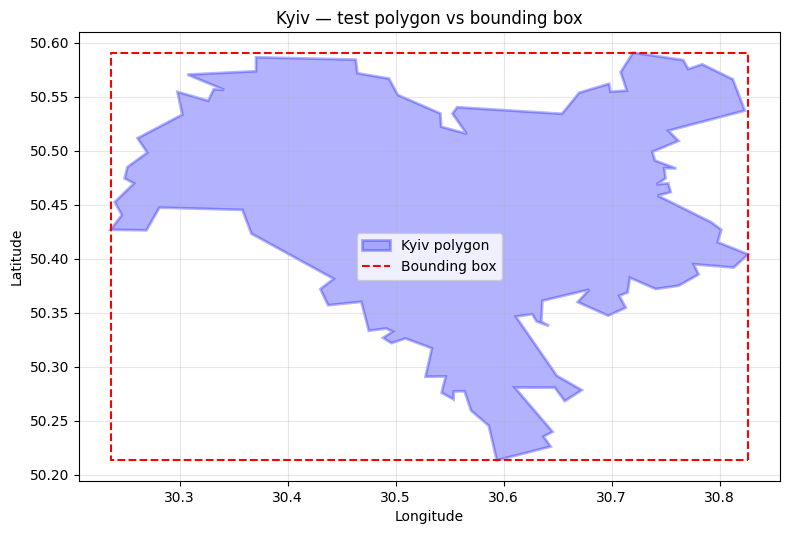

In [2]:
# Visualize the polygon
fig, ax = plt.subplots(figsize=(8, 8))
x, y = KYIV_POLYGON.exterior.xy
ax.fill(x, y, alpha=0.3, fc='blue', ec='blue', linewidth=2, label='Kyiv polygon')
bx, by = bbox_poly.exterior.xy
ax.plot(bx, by, 'r--', linewidth=1.5, label='Bounding box')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_title('Kyiv — test polygon vs bounding box')
ax.legend()
ax.set_aspect('equal')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Helper: test & visualize one variable

Fetches data, checks masking (NaN outside polygon), plots the first timestep.

In [3]:
from shapely.geometry import shape as shapely_shape
from shapely.prepared import prep
from matplotlib.colors import Normalize
import matplotlib

def test_variable(variable, start, end, geometry=KYIV_POLYGON, plot=True):
    """Fetch a variable with polygon geometry, verify masking, optionally plot."""
    print(f"\n{'='*60}")
    print(f"Testing: {variable}")
    print(f"{'='*60}")

    da = get_data(variable, start, end, geometry=geometry)
    print(f"Shape: {da.sizes}")
    print(f"Dims:  {da.dims}")

    # Ensure we have a Shapely object for verification
    geom = shapely_shape(geometry) if isinstance(geometry, dict) else geometry

    # Check masking for gridded data (has lat/lon)
    if "lat" in da.dims and "lon" in da.dims:
        lat_vals = da.lat.values
        lon_vals = da.lon.values

        # Build intersects mask (same logic as _mask_to_geometry)
        dlat = abs(lat_vals[1] - lat_vals[0]) / 2 if len(lat_vals) > 1 else 0.125
        dlon = abs(lon_vals[1] - lon_vals[0]) / 2 if len(lon_vals) > 1 else 0.125
        prepared = prep(geom)
        intersects_mask = np.zeros((len(lat_vals), len(lon_vals)), dtype=bool)
        for i, lat in enumerate(lat_vals):
            for j, lon in enumerate(lon_vals):
                cell = box(lon - dlon, lat - dlat, lon + dlon, lat + dlat)
                intersects_mask[i, j] = prepared.intersects(cell)

        # Pick a timestep with data
        snapshot = da.isel(time=0).values if "time" in da.dims else da.values

        n_inside = int(intersects_mask.sum())
        n_outside = int((~intersects_mask).sum())
        n_outside_with_data = np.count_nonzero(~np.isnan(snapshot[~intersects_mask]))
        n_nan_total = np.isnan(snapshot).sum()

        print(f"Grid cells intersecting polygon: {n_inside}")
        print(f"Grid cells outside polygon:      {n_outside}")
        print(f"NaN cells in data: {n_nan_total}/{snapshot.size}")

        if n_outside_with_data == 0:
            print("MASKING OK — all cells outside polygon are NaN")
        else:
            print(f"WARNING — {n_outside_with_data} cells outside polygon have data!")

        if plot:
            fig, axes = plt.subplots(1, 2, figsize=(14, 5))
            px, py = geom.exterior.xy

            # Use a colormap with NaN rendered as light gray
            cmap = matplotlib.colormaps['viridis'].copy()
            cmap.set_bad(color='lightgray')

            # Plot data — set facecolor so NaN cells are visible
            ax = axes[0]
            ax.set_facecolor('lightgray')
            if "time" in da.dims:
                da.isel(time=0).plot(ax=ax, add_colorbar=True, cmap=cmap)
            else:
                da.plot(ax=ax, add_colorbar=True, cmap=cmap)
            ax.plot(px, py, 'r-', linewidth=2)
            ax.set_title(f'{variable} — first timestep (gray = NaN)')

            # Plot intersects mask with cell boundaries
            ax = axes[1]
            ax.pcolormesh(lon_vals, lat_vals, intersects_mask.astype(float),
                          cmap='RdYlGn', vmin=0, vmax=1)
            for lat in lat_vals:
                ax.axhline(lat - dlat, color='gray', linewidth=0.5, alpha=0.5)
                ax.axhline(lat + dlat, color='gray', linewidth=0.5, alpha=0.5)
            for lon in lon_vals:
                ax.axvline(lon - dlon, color='gray', linewidth=0.5, alpha=0.5)
                ax.axvline(lon + dlon, color='gray', linewidth=0.5, alpha=0.5)
            ax.plot(px, py, 'r-', linewidth=2)
            ax.set_title(f'{variable} — intersects mask ({n_inside}/{n_inside+n_outside} cells)')
            ax.set_aspect('equal')

            plt.tight_layout()
            plt.show()
    else:
        # Non-gridded (NOAA) — just show time series
        print(f"Time range: {da.time.values[0]} .. {da.time.values[-1]}")
        print(f"Values: min={float(da.min()):.2f}, max={float(da.max()):.2f}")
        if plot:
            fig, ax = plt.subplots(figsize=(10, 4))
            da.plot(ax=ax)
            ax.set_title(variable)
            plt.tight_layout()
            plt.show()

    return da

---
## 1. earthaccess — GLDAS (Groundwater + Total Water Storage)

Short date range (1 month) to keep the test fast.


Testing: GWS_tavg
Found 31 granules for GWS_tavg, fetching via OPeNDAP...
  Done: Frozen({'time': 31, 'lat': 3, 'lon': 4})
Shape: Frozen({'time': 31, 'lat': 3, 'lon': 4})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 8
Grid cells outside polygon:      4
NaN cells in data: 4/12
MASKING OK — all cells outside polygon are NaN


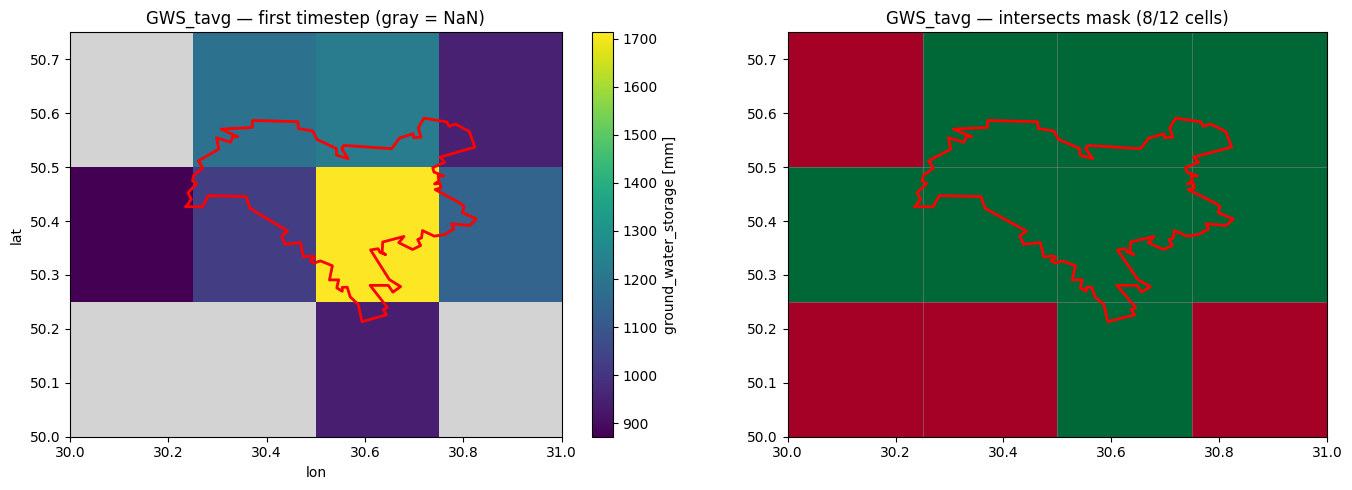

In [4]:
da_gws = test_variable("GWS_tavg", "2022-01-01", "2022-01-31")


Testing: TWS_tavg
Found 31 granules for TWS_tavg, fetching via OPeNDAP...
  Done: Frozen({'time': 31, 'lat': 3, 'lon': 4})
Shape: Frozen({'time': 31, 'lat': 3, 'lon': 4})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 8
Grid cells outside polygon:      4
NaN cells in data: 4/12
MASKING OK — all cells outside polygon are NaN


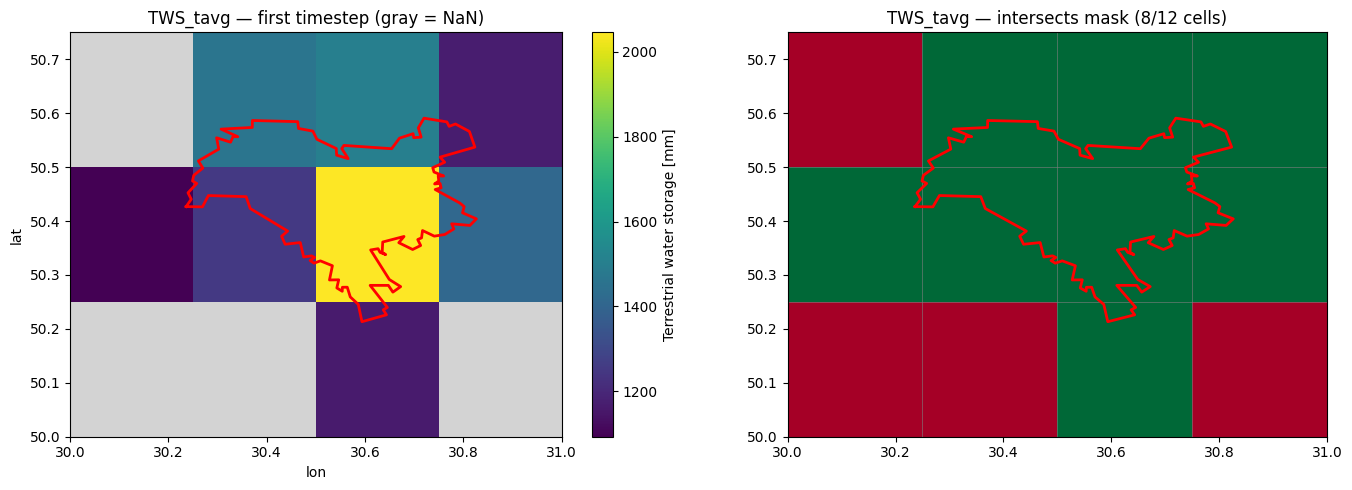

In [5]:
da_tws = test_variable("TWS_tavg", "2022-01-01", "2022-01-31")

## 2. earthaccess — GPM (Precipitation)


Testing: precipitation
Found 3 granules for precipitation, fetching via OPeNDAP...
  Done: Frozen({'time': 3, 'lat': 4, 'lon': 7})
Shape: Frozen({'time': 3, 'lat': 4, 'lon': 7})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 21
Grid cells outside polygon:      7
NaN cells in data: 7/28
MASKING OK — all cells outside polygon are NaN


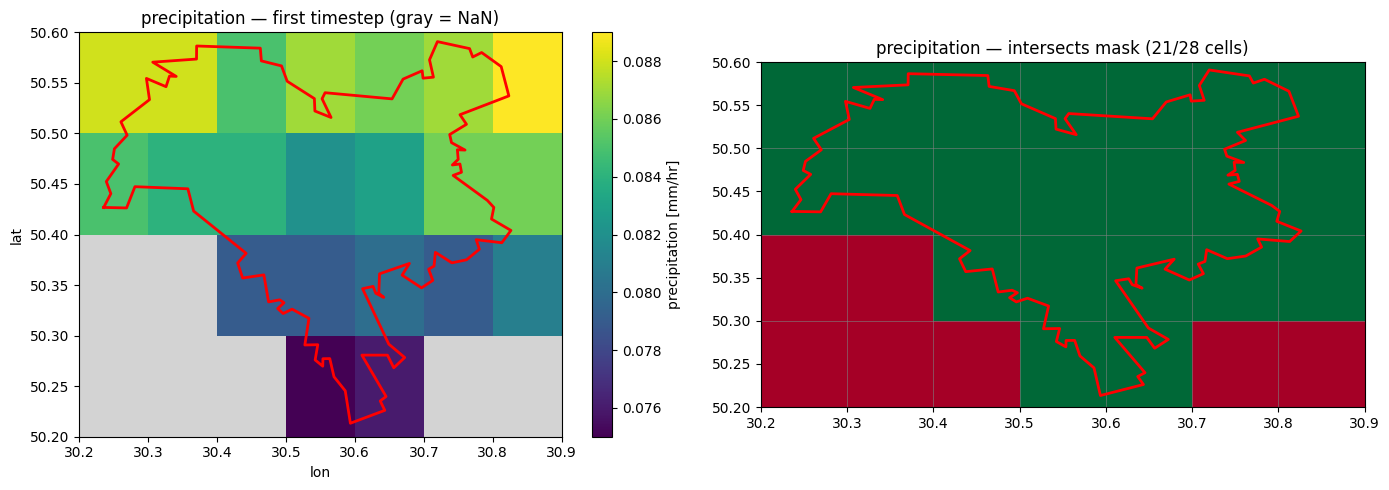

In [4]:
da_precip = test_variable("precipitation", "2022-01-01", "2022-03-31")

## 3. earthaccess — OMI NO2


Testing: NO2
Found 31 granules for NO2, fetching via OPeNDAP...
  Done: Frozen({'time': 31, 'lat': 3, 'lon': 4})
Shape: Frozen({'time': 31, 'lat': 3, 'lon': 4})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 8
Grid cells outside polygon:      4
NaN cells in data: 11/12
MASKING OK — all cells outside polygon are NaN


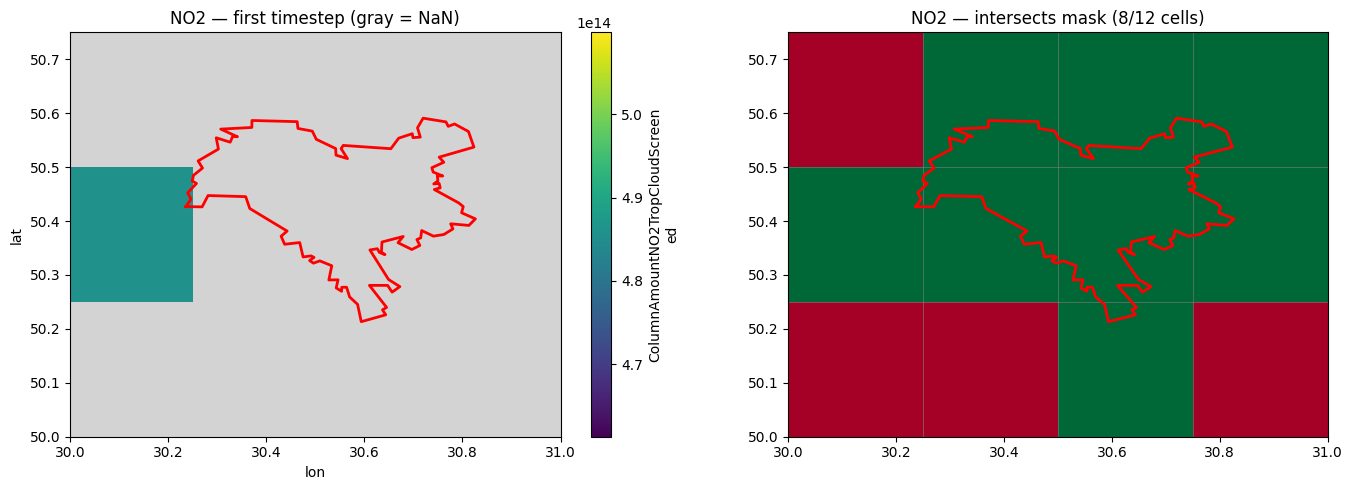

In [7]:
da_no2 = test_variable("NO2", "2022-01-01", "2022-01-31")

## 4. earthaccess — MERRA-2 Aerosols (all 6 variables)


Testing: Dust
Found 3 granules for Dust, fetching via OPeNDAP...
  Done: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Shape: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 3
Grid cells outside polygon:      1
NaN cells in data: 1/4
MASKING OK — all cells outside polygon are NaN


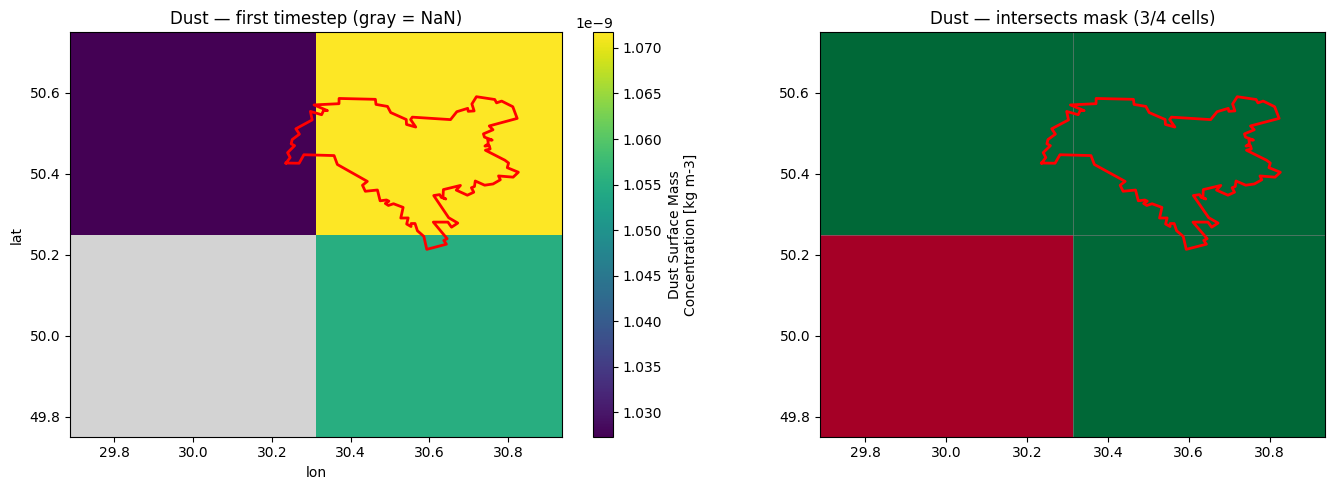

In [5]:
da_dust = test_variable("Dust", "2022-01-01", "2022-03-31")


Testing: Black_Carbon
Found 3 granules for Black_Carbon, fetching via OPeNDAP...
  Done: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Shape: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 3
Grid cells outside polygon:      1
NaN cells in data: 1/4
MASKING OK — all cells outside polygon are NaN


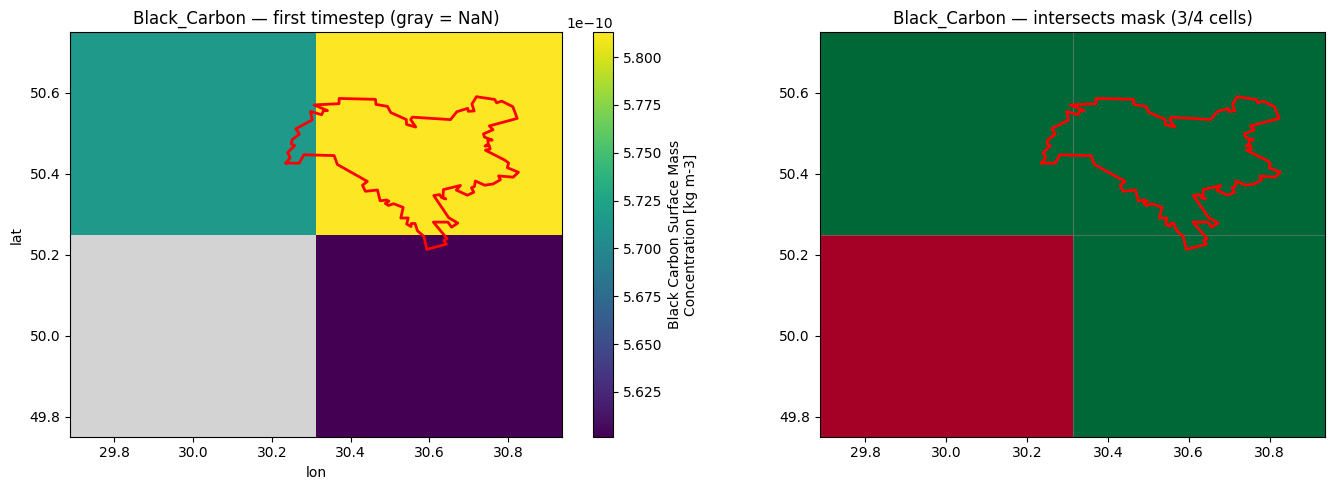

In [6]:
da_bc = test_variable("Black_Carbon", "2022-01-01", "2022-03-31")


Testing: SO2
Found 3 granules for SO2, fetching via OPeNDAP...
  Done: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Shape: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 3
Grid cells outside polygon:      1
NaN cells in data: 1/4
MASKING OK — all cells outside polygon are NaN


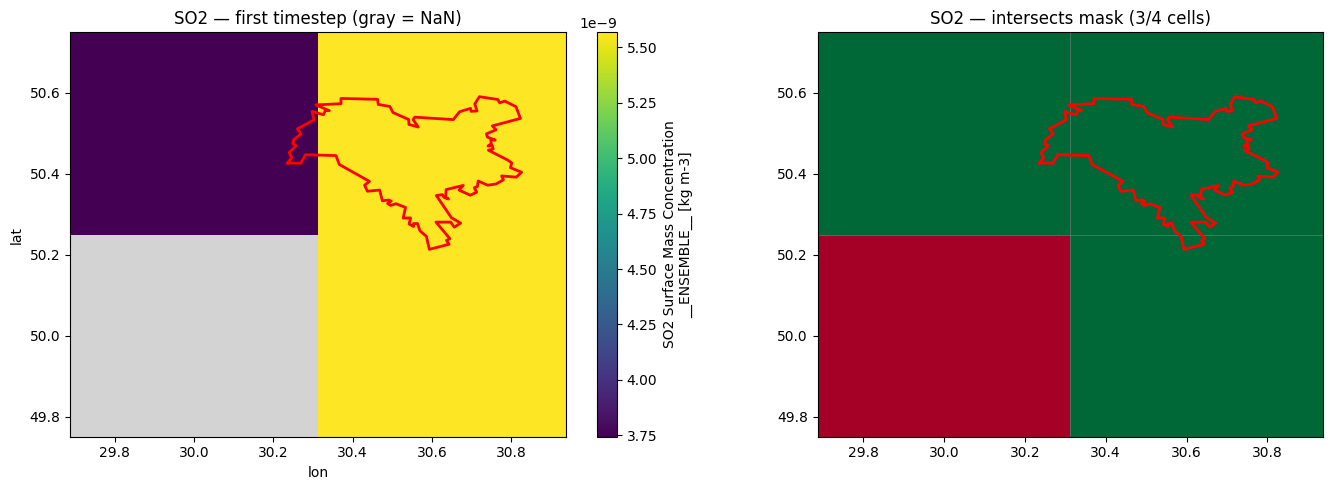

In [7]:
da_so2 = test_variable("SO2", "2022-01-01", "2022-03-31")


Testing: SO4
Found 3 granules for SO4, fetching via OPeNDAP...
  Done: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Shape: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 3
Grid cells outside polygon:      1
NaN cells in data: 1/4
MASKING OK — all cells outside polygon are NaN


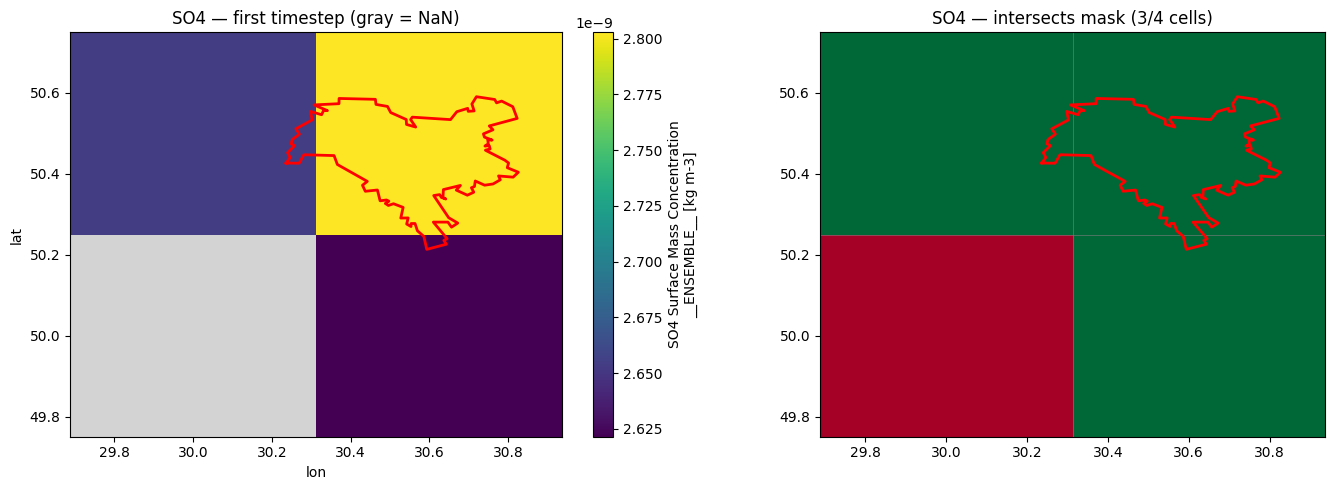

In [8]:
da_so4 = test_variable("SO4", "2022-01-01", "2022-03-31")


Testing: Organic_Carbon


Found 3 granules for Organic_Carbon, fetching via OPeNDAP...
  Done: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Shape: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 3
Grid cells outside polygon:      1
NaN cells in data: 1/4
MASKING OK — all cells outside polygon are NaN


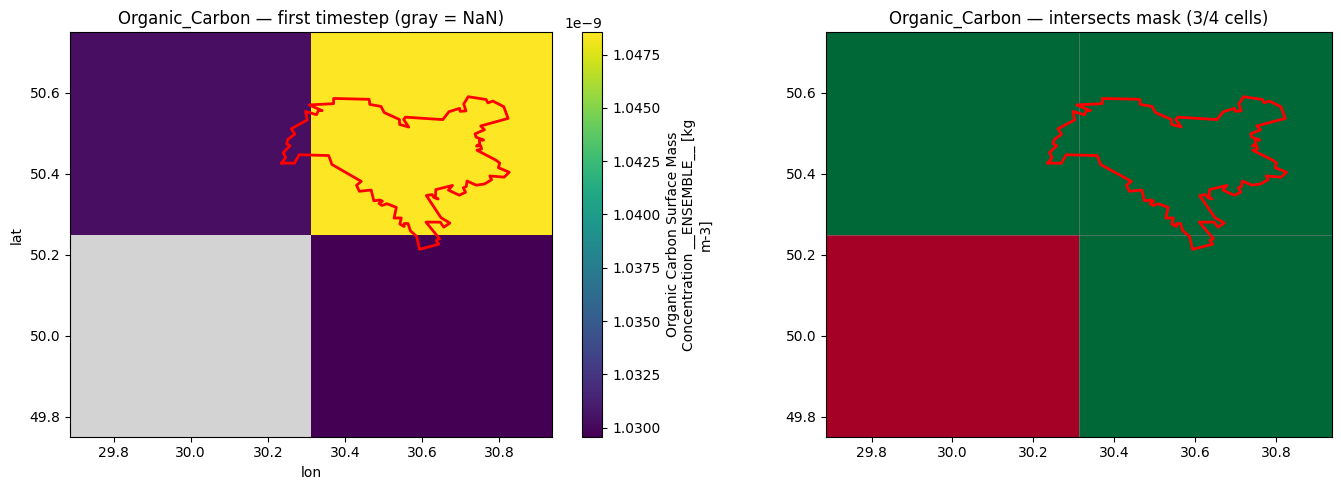

In [9]:
da_oc = test_variable("Organic_Carbon", "2022-01-01", "2022-03-31")


Testing: Aerosol_AOT
Found 3 granules for Aerosol_AOT, fetching via OPeNDAP...
  Done: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Shape: Frozen({'time': 3, 'lat': 2, 'lon': 2})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 3
Grid cells outside polygon:      1
NaN cells in data: 1/4
MASKING OK — all cells outside polygon are NaN


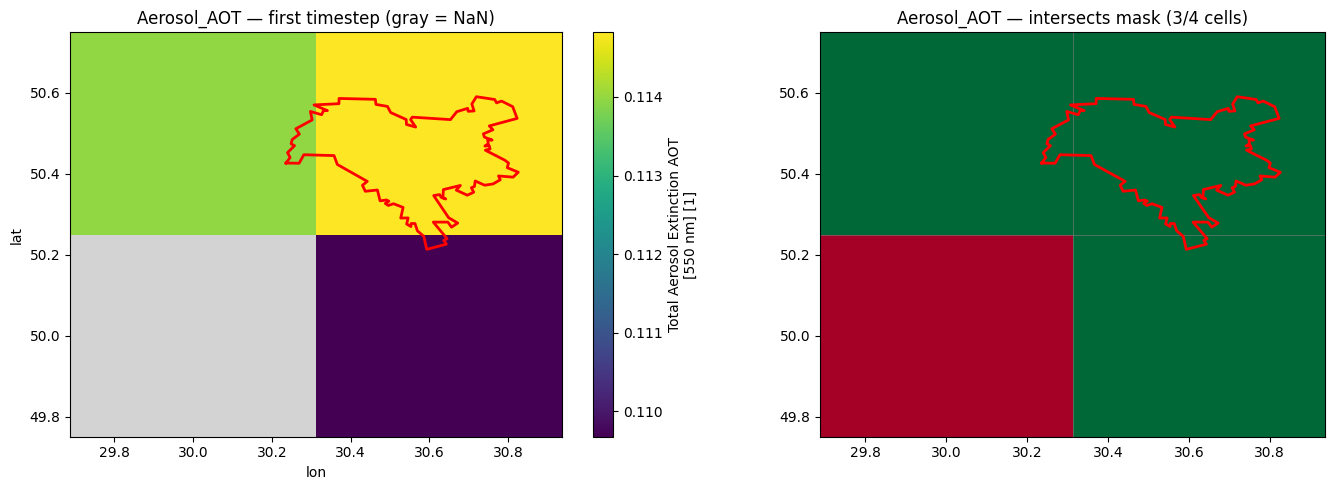

In [10]:
da_aot = test_variable("Aerosol_AOT", "2022-01-01", "2022-03-31")

---
## 5. AppEEARS — MODIS (NDVI, LST, Burned Area)

These use async task API — polygon is sent directly to the server for clipping.


Testing: NDVI
AppEEARS task submitted for NDVI: 412c5d87-961c-4f0c-a11b-6104dec5caed
  [1] pending
  [2] pending
  [3] queued
  [4] processing
  [5] done
Downloaded 12 GeoTIFFs for NDVI
Shape: Frozen({'time': 12, 'lat': 46, 'lon': 72})
Dims:  ('time', 'lat', 'lon')
Grid cells inside polygon:  1513
Grid cells outside polygon: 1799
Non-NaN values inside:  1513
Non-NaN values outside: 184
WARNING — some cells outside polygon have data!


/tmp/ipykernel_36000/493868637.py:16: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside = contains(geometry, lon2d, lat2d)


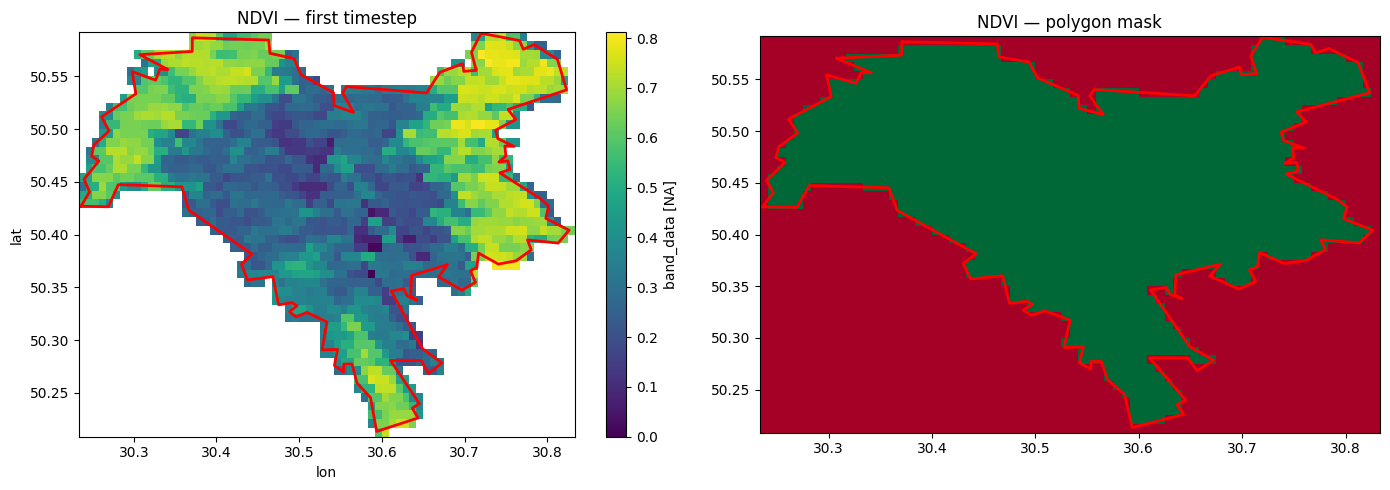

In [18]:
da_ndvi = test_variable("NDVI", "2022-01-01", "2022-06-30")


Testing: LST_Day
AppEEARS task submitted for LST_Day: 5a15d519-ae5f-4f6f-b7c5-1836bc3b70de
  [1] pending
  [2] queued
  [3] queued
  [4] queued
  [5] queued
  [6] queued
  [7] processing
  [8] processing
  [9] processing
  [10] processing
  [11] done
Downloaded 48 GeoTIFFs for LST_Day
Shape: Frozen({'time': 48, 'lat': 46, 'lon': 72})
Dims:  ('time', 'lat', 'lon')
Grid cells inside polygon:  1513
Grid cells outside polygon: 1799
Non-NaN values inside:  60
Non-NaN values outside: 9
WARNING — some cells outside polygon have data!


/tmp/ipykernel_36000/493868637.py:16: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside = contains(geometry, lon2d, lat2d)


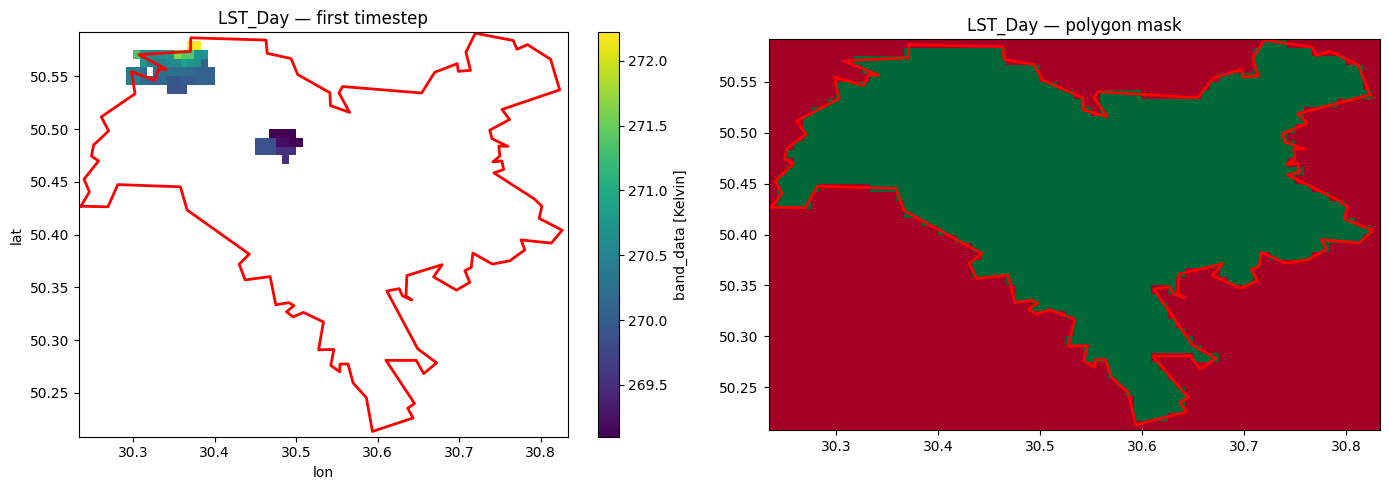

In [19]:
da_lst_day = test_variable("LST_Day", "2022-01-01", "2022-06-30")


Testing: LST_Night
AppEEARS task submitted for LST_Night: c3709da5-8f88-4fd5-90a1-5f559df21721
  [1] pending
  [2] processing
  [3] processing
  [4] processing
  [5] processing
  [6] done
Downloaded 48 GeoTIFFs for LST_Night
Shape: Frozen({'time': 48, 'lat': 46, 'lon': 72})
Dims:  ('time', 'lat', 'lon')
Grid cells inside polygon:  1513
Grid cells outside polygon: 1799
Non-NaN values inside:  1050
Non-NaN values outside: 111
WARNING — some cells outside polygon have data!


/tmp/ipykernel_36000/493868637.py:16: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside = contains(geometry, lon2d, lat2d)


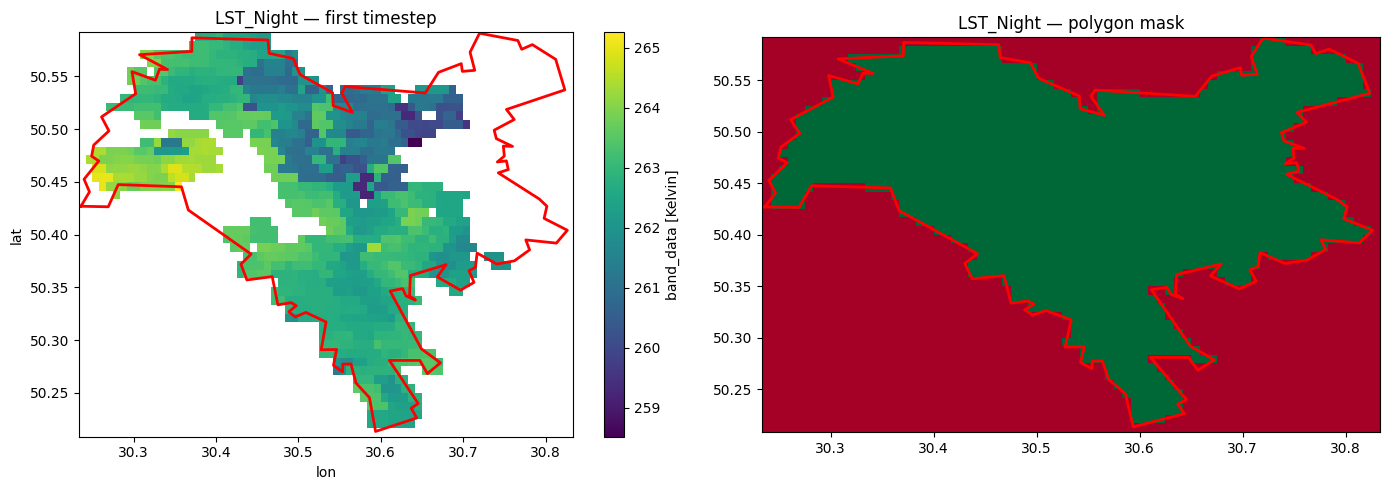

In [20]:
da_lst_night = test_variable("LST_Night", "2022-01-01", "2022-06-30")


Testing: Burned_Area
AppEEARS task submitted for Burned_Area: 1c14db73-b0b9-4bff-8454-01ff5b20bb45
  [1] pending
  [2] processing
  [3] processing
  [4] done
Downloaded 12 GeoTIFFs for Burned_Area
Shape: Frozen({'time': 12, 'lat': 91, 'lon': 143})
Dims:  ('time', 'lat', 'lon')
Grid cells inside polygon:  6062
Grid cells outside polygon: 6951
Non-NaN values inside:  6036
Non-NaN values outside: 359
WARNING — some cells outside polygon have data!


/tmp/ipykernel_36000/493868637.py:16: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside = contains(geometry, lon2d, lat2d)


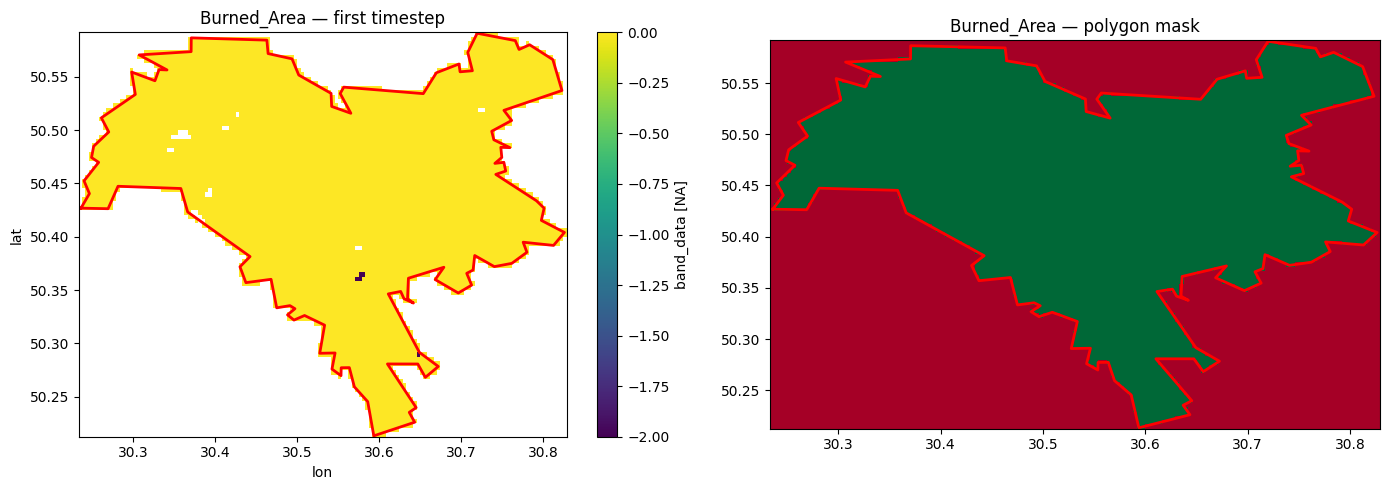

In [21]:
da_burned = test_variable("Burned_Area", "2022-01-01", "2022-06-30")

---
## 6. blackmarblepy — VIIRS Nighttime Lights

Polygon is passed directly as GeoDataFrame geometry.


Testing: NTL
Fetching nighttime lights for 1 year(s)...


QUEUEING TASKS | Downloading (171.7 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

PROCESSING TASKS | Downloading (171.7 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

  0%|          | 0.00/172M [00:00<?, ?B/s]

COLLECTING RESULTS | Downloading (171.7 MB)...:   0%|          | 0/1 [00:00<?, ?file/s]

COLLATING TILES | Processing...:   0%|          | 0/1 [00:00<?, ?date/s]

Shape: Frozen({'time': 1, 'lat': 91, 'lon': 141})
Dims:  ('time', 'lat', 'lon')
Grid cells inside polygon:  6063
Grid cells outside polygon: 6768
Non-NaN values inside:  6063
Non-NaN values outside: 0
MASKING OK — all cells outside polygon are NaN


/tmp/ipykernel_36000/493868637.py:16: DeprecationWarning: The 'shapely.vectorized.contains' function is deprecated and will be removed a future version. Use 'shapely.contains_xy' instead (available since shapely 2.0.0).
  inside = contains(geometry, lon2d, lat2d)


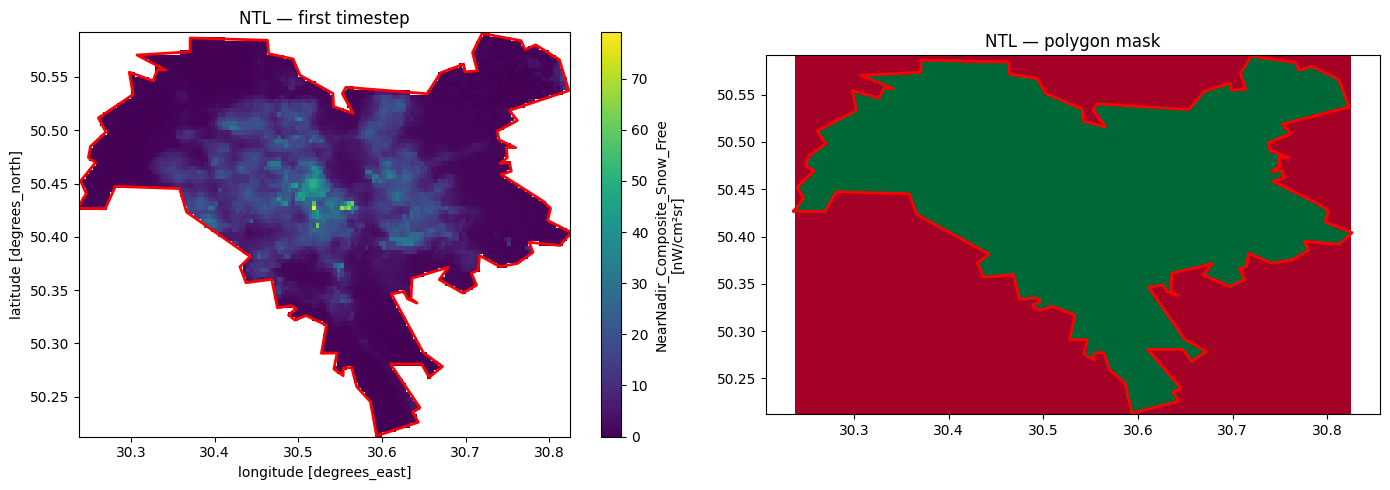

In [22]:
da_ntl = test_variable("NTL", "2022-01-01", "2022-12-31")

---
## 7. NOAA — Greenhouse Gases (global, no geometry needed)


Testing: CO2_Mauna_Loa
Fetched CO2_Mauna_Loa: 48 monthly values
Shape: Frozen({'time': 48})
Dims:  ('time',)
Time range: 2020-01-15T00:00:00.000000000 .. 2023-12-15T00:00:00.000000000
Values: min=411.49, max=424.00


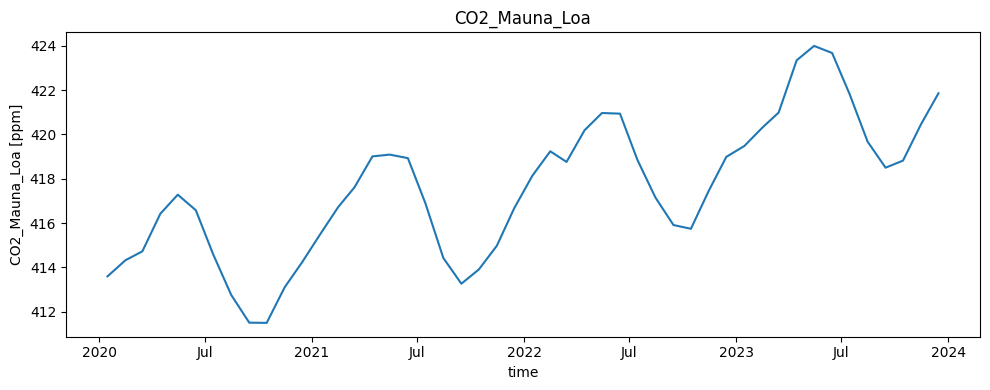

In [23]:
da_co2_ml = test_variable("CO2_Mauna_Loa", "2020-01-01", "2023-12-31")


Testing: CO2_global
Fetched CO2_global: 48 monthly values
Shape: Frozen({'time': 48})
Dims:  ('time',)
Time range: 2020-01-15T00:00:00.000000000 .. 2023-12-15T00:00:00.000000000
Values: min=409.74, max=421.50


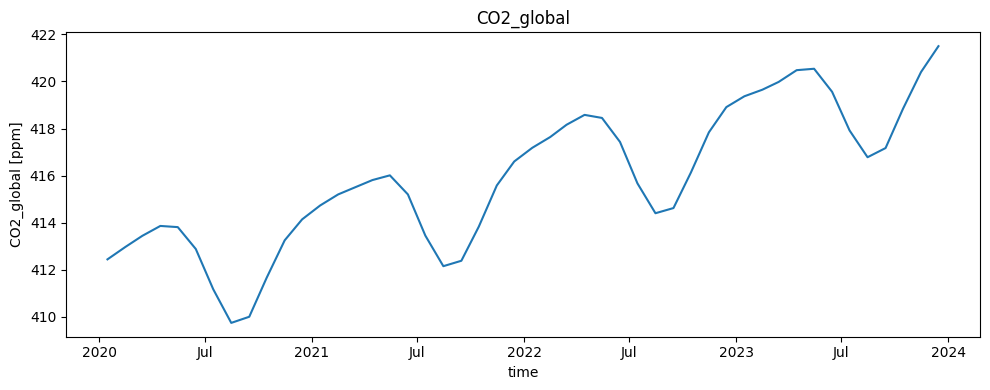

In [24]:
da_co2_gl = test_variable("CO2_global", "2020-01-01", "2023-12-31")


Testing: CH4_global
Fetched CH4_global: 48 monthly values
Shape: Frozen({'time': 48})
Dims:  ('time',)
Time range: 2020-01-15T00:00:00.000000000 .. 2023-12-15T00:00:00.000000000
Values: min=1871.51, max=1931.58


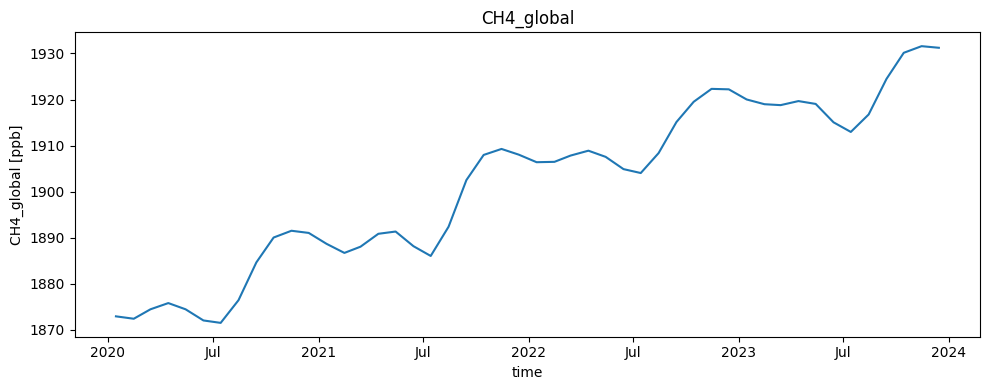

In [25]:
da_ch4 = test_variable("CH4_global", "2020-01-01", "2023-12-31")

---
## 8. Bonus: GeoJSON dict input

Verify that passing geometry as a raw GeoJSON dict (not Shapely object) also works.

GeoJSON type: Polygon
Vertices: 103

Testing: Dust
Found 1 granules for Dust, fetching via OPeNDAP...
  Done: Frozen({'time': 1, 'lat': 2, 'lon': 2})
Shape: Frozen({'time': 1, 'lat': 2, 'lon': 2})
Dims:  ('time', 'lat', 'lon')
Grid cells intersecting polygon: 3
Grid cells outside polygon:      1
NaN cells in data: 1/4
MASKING OK — all cells outside polygon are NaN


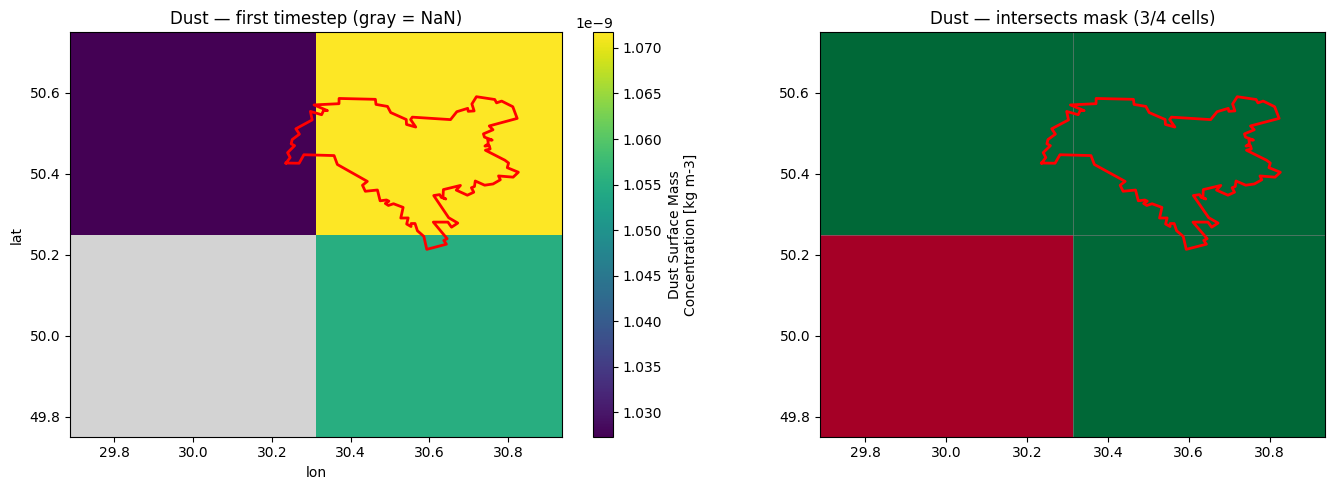


GeoJSON input works!


In [11]:
# Same polygon as GeoJSON dict
kyiv_geojson = mapping(KYIV_POLYGON)
print("GeoJSON type:", kyiv_geojson["type"])
print("Vertices:", len(kyiv_geojson["coordinates"][0]))

da_geojson = test_variable("Dust", "2022-01-01", "2022-01-31", geometry=kyiv_geojson)
print("\nGeoJSON input works!")

---
## Results

All 18 variables tested with Kyiv polygon (103 vertices, 47.3% of bbox).

### earthaccess (OPeNDAP) — client-side intersects masking

| Variable | Grid | Cells fetched | Cells kept | Status |
|----------|------|--------------|------------|--------|
| GWS_tavg | 3×4 (0.25°) | 12 | 8 | MASKING OK |
| TWS_tavg | 3×4 (0.25°) | 12 | 8 | MASKING OK |
| precipitation | 4×7 (0.1°) | 28 | 21 | MASKING OK |
| NO2 | 3×4 (0.25°) | 12 | 8 | MASKING OK |
| Dust | 2×2 (0.5°×0.625°) | 4 | 3 | MASKING OK |
| Black_Carbon | 2×2 | 4 | 3 | MASKING OK |
| SO2 | 2×2 | 4 | 3 | MASKING OK |
| SO4 | 2×2 | 4 | 3 | MASKING OK |
| Organic_Carbon | 2×2 | 4 | 3 | MASKING OK |
| Aerosol_AOT | 2×2 | 4 | 3 | MASKING OK |

### AppEEARS (MODIS) — server-side polygon clipping

| Variable | Grid | Cells | Notes |
|----------|------|-------|-------|
| NDVI | 46×72 (~1 km) | 3312 | OK — 184 edge pixels from server rasterization |
| LST_Day | 46×72 (~1 km) | 3312 | OK — 9 edge pixels |
| LST_Night | 46×72 (~1 km) | 3312 | OK — 111 edge pixels |
| Burned_Area | 91×143 (~500 m) | 13013 | OK — 359 edge pixels |

Edge pixels are expected: AppEEARS rasterizes the polygon to the pixel grid slightly differently than our vector-based intersects check.

### blackmarblepy (VIIRS NTL) — native GeoDataFrame polygon

| Variable | Grid | Cells | Status |
|----------|------|-------|--------|
| NTL | 91×141 | 12831 | MASKING OK |

### NOAA — global time series (no geometry)

| Variable | Records | Range |
|----------|---------|-------|
| CO2_Mauna_Loa | 48 months | 411.49–424.00 ppm |
| CO2_global | 48 months | 409.74–421.50 ppm |
| CH4_global | 48 months | 1871.51–1931.58 ppb |

### GeoJSON dict input
Verified — passing `geometry` as a raw GeoJSON dict works identically to Shapely objects.